In [ ]:
!pip install gitpython
import os, shutil
from git import Repo

try:
    # Check if this cell is running in google colab
    import google.colab

    # Delete everything in the content (current) directory on google colab
    for root, dirs, files in os.walk("/content"):
        for name in files:
            os.remove(os.path.join(root, name))
        for name in dirs:
            shutil.rmtree(os.path.join(root, name))
        break

    # Clone git repo, change the branch and
    Repo.clone_from("https://gitlab.socsci.ru.nl/snnsimulator/simsnn.git", "/content/simsnnn")

    # Move the repo up by one level in the folder hierarchy
    for root, dirs, files in os.walk("/content/simsnnn"):
        for name in dirs + files:
            shutil.move(os.path.join(root, name), os.path.join("/content", name))
        break
    os.rmdir("/content/simsnnn")

except:
    print("This cell is only supposed to be executed on google colab, not on your local machine!")

# 5.1 Add two integers represented as the time when a neuron spikes

Rasterdata:
[[False  True False False False False False]
 [False False  True False False False False]
 [False False  True  True  True  True  True]
 [False False False  True  True  True  True]
 [False False False  True False False False]
 [False False False False False  True False]
 [ True  True  True  True  True  True  True]]

Multimeterdata:
[[0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [6. 6. 6. 5. 6. 0. 1.]
 [0. 0. 1. 1. 1. 1. 1.]
 [0. 0. 0. 1. 1. 1. 1.]
 [1. 1. 1. 1. 1. 1. 1.]]


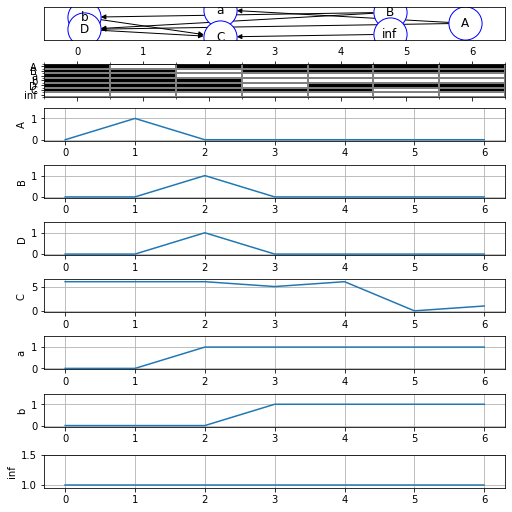

In [37]:
from simsnn.core.networks import Network
from simsnn.core.simulators import Simulator

net = Network()
sim = Simulator(net)

# assertion: N > min(A,B)
N = 7 

# Inputs
# A = 1 and B = 2
A = net.createInputTrain(train=[0,1], loop=False, ID="A")
B = net.createInputTrain(train=[0,0,1], loop=False, ID="B") 
# C spikes at A+B+2 = 1+1+2 = 4

# LIF neurons
# Paper says that m should be 0 for a, b and inf, 
# but they do not act like they do in the paper, which is 
# why I changed this value to 1. Now, they keep spiking when they need to.
a = net.createLIF(ID="a", thr=1, V_reset=1, m=1)
b = net.createLIF(ID="b", thr=1, V_reset=1, m=1)
D = net.createLIF(ID="D", thr=2, V_reset=0, m=1)
C = net.createLIF(ID="C", thr=N, V_reset=0, m=1, V_init=N-1) 
inf = net.createLIF(ID="inf", thr=1, V_reset=1, m=1, V_init=1)

# Synapses
net.createSynapse(pre=A, post=D, ID="A-D", d=1, w=1)
net.createSynapse(pre=B, post=D, ID="B-D", d=1, w=1)
net.createSynapse(pre=A, post=a, ID="A-a", d=1, w=1)
net.createSynapse(pre=B, post=b, ID="B-b", d=1, w=1)
net.createSynapse(pre=D, post=C, ID="D-C", d=1, w=1)
net.createSynapse(pre=a, post=C, ID="a-C", d=2, w=1)
net.createSynapse(pre=b, post=C, ID="b-C", d=2, w=1)
net.createSynapse(pre=inf, post=C, ID="inf-C", d=3, w=-1)

# Plot
sim.raster.addTarget([A, B, a, b, D, C, inf])
sim.multimeter.addTarget([A, B, D, C, a, b, inf])
sim.run(steps=N, plotting=True)

# Analysis of Adding two integers represented as the time when a neuron spikes

Sum of A and B is seen at spike C - 2. Here, A = 1 and B = 2 which gives a spike at C = 5, so we substract 2 to get the sum = 3.

## Energy complexity
We assume from the paper that A $\leq$ B
* C spikes as many times as A+B+delay, where delay is 2. This gives us the complexity of A + B + 2
* One spike per time point for the inf neuron, which is A + B + 2
* A and B fire only once, representing their value. Complexity = 1 + 1 = 2
* a and b fire infinitely after A and B fire respectively, but they only need to fire until C is computed, which is C - A and C - B respectively. Which gives complexity = ((A + B + 2) - A) + ((A + B + 2) - B) = A + B + 4
* D fires only once as well (after B at most, as B is the bigger number). Complexity = 1

We can compute the total energy complexity by adding all these complexities:  \\
A + B + 2 + 2 + A + B + 2 + A + B + 4 + 1 = 3A + 3B + 11 = $O(A + B)$, as constants can be removed.

## Space complexity
Memory does not have to be changed for an additional computation, as memory is stored in the neurons, spikes and the delay. This causes the space complexity to be constant and thus be reduced to its smallest form: $O(1)$

## Time complexity
The time of the computation completely relies on the input, which are A and B. Spikes will keep going until A+B+2, which is how long it will take. That gives us the complexity $O(A+B)$, as 2 is a constant and can be removed.

# 5.2  Add multiple integers represented as the time when a neuron spikes


Rasterdata:
[[False  True False False False False False False False False False False]
 [False False False False  True False False False False False False False]
 [False  True False False False False False False False False False False]
 [False False  True False False False False False False False False False]
 [False False False  True  True  True  True  True  True  True  True  True]
 [False False False False False False  True  True  True  True  True  True]
 [False False False  True  True  True  True  True  True  True  True  True]
 [False False False False False  True False False False False False False]
 [False False False False False False False False False False  True False]
 [ True  True  True  True  True  True  True  True  True  True  True  True]]

Multimeterdata:
[[ 0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [11. 11. 11.  8

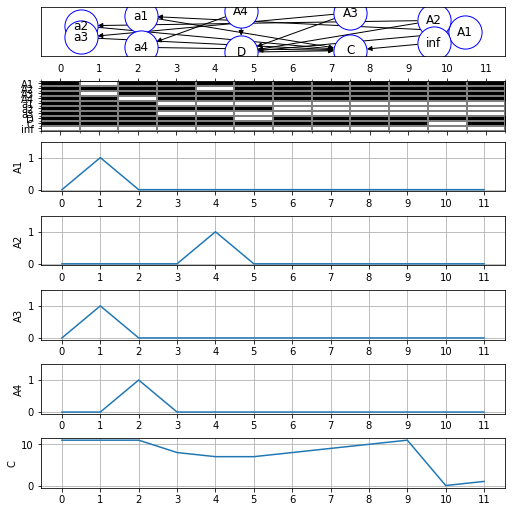

In [43]:
from simsnn.core.networks import Network
from simsnn.core.simulators import Simulator

net = Network()
sim = Simulator(net)

# Assertion: N > A1 + A2 + A3 + A4 - max(A1, A2, A3, A4)
# and N >=1
# M = Amount of numbers
N = 12
M = 4 

# A1, A2, A3, A4 = 1, 4, 1, 2, which gives C = 8 + 2 = 10
A1 = net.createInputTrain(train=[0, 1], loop=False, ID="A1")
A2 = net.createInputTrain(train=[0, 0, 0, 0, 1], loop=False, ID="A2")
A3 = net.createInputTrain(train=[0, 1], loop=False, ID="A3") 
A4 = net.createInputTrain(train=[0, 0, 1], loop=False, ID="A4") 

# LIF neurons
a1 = net.createLIF(ID="a1", thr=1, V_reset=1, m=1)
a2 = net.createLIF(ID="a2", thr=1, V_reset=1, m=1)
a3 = net.createLIF(ID="a3", thr=1, V_reset=1, m=1)
a4 = net.createLIF(ID="a4", thr=1, V_reset=1, m=1)
D = net.createLIF(ID="D", thr=M, V_reset=0, m=1)
C = net.createLIF(ID="C", thr=N, V_reset=0, m=1, V_init=N-1)
inf = net.createLIF(ID="inf", thr=1, V_reset=1, m=1, V_init=1)

# Synapses
net.createSynapse(pre=A1, post=D, ID="A1-D", d=1, w=1)
net.createSynapse(pre=A2, post=D, ID="A2-D", d=1, w=1)
net.createSynapse(pre=A3, post=D, ID="A3-D", d=1, w=1)
net.createSynapse(pre=A4, post=D, ID="A4-D", d=1, w=1)
net.createSynapse(pre=A1, post=a1, ID="A1-a1", d=2, w=1)
net.createSynapse(pre=A2, post=a2, ID="A2-a2", d=2, w=1)
net.createSynapse(pre=A3, post=a3, ID="A3-a3", d=2, w=1)
net.createSynapse(pre=A4, post=a4, ID="A4-a4", d=2, w=1)
net.createSynapse(pre=D, post=C, ID="D-C", d=1, w=1)
net.createSynapse(pre=a1, post=C, ID="a1-C", d=1, w=1)
net.createSynapse(pre=a2, post=C, ID="a2-C", d=1, w=1)
net.createSynapse(pre=a3, post=C, ID="a3-C", d=1, w=1)
net.createSynapse(pre=a4, post=C, ID="a4-C", d=1, w=1)
net.createSynapse(pre=inf, post=C, ID="inf-C", d=3, w=-(M-1))

# Plot
sim.raster.addTarget([A1, A2, A3, A4, a1, a2, a3, D, C, inf])
sim.multimeter.addTarget([A1, A2, A3, A4, C])
sim.run(steps=N, plotting=True)

# Analysis of Add multiple integers represented as the time when a neuron spikes

Similar to the previous example SNN, C (sum) will spike at $\sum_{i}^{M} A_i + 2$. There are M numbers to be added. $A_i$ represents the value of each neuron to be added with respect to the $i^{th}$ neuron.

## Energy complexity
The same procedure is done as in the previous exercise.
* C spikes as many times as $\sum_{i}^{M} A_i + $delay, where delay is 2. This gives us the complexity of $(A_1 + A_2 + ... + A_m)$, because 2 is a constant, it can be removed
* All neurons $A_i$ fire only once to represent the value they add to the sum. This gives the complexity M, as there are M neurons
* The inf neuron spikes as many times as C, which is $(A_1 + A_2 + ... + A_m) + 2$. Removing constants gives $(A_1 + A_2 + ... + A_m)$.
* D only spikes once -> complexity of 1
* $a_i$ spikes $C - (A_i)$ times for every neuron $i$ which gives complexity:\
$((C - A_1) + (C - A_2) + ... + (C - A_m))$. This can be rewritten to $((A_1 + A_2 + ... + A_m) - C * M)$

When we add these complexities, we get: \
$(A_1 + A_2 + ... + A_m) + M + (A_1 + A_2 + ... + A_m) + 1 + (A_1 + A_2 + ... + A_m) - C * M=$\
$M + 2(A_1 + A_2 + ... + A_m) + (A_1 + A_2 + ... + A_m) - C * M$ =\
$M + 3(A_1 + A_2 + ... + A_m) - C * M$, filling in C gives:
$M + 3(A_1 + A_2 + ... + A_m) - M*(A_1 + A_2 + ... + A_m)$ \
As the first $M$ is adding a constant, we can remove it. After this we can merge the two terms:\
$(3-M)(A_1 + A_2 + ... + A_m)$\
3 is again a constant, so we can remove it and rewrite the formula, as $-M = M$ in complexity.\
This gives us the final complexity:\
$O(M(A_1+...+A_M))$

## Space complexity
Space complexity is the memory used. This only increases here based on the number of neurons that consist of the sum. This value is the variable $M$ in the paper, which is why the space complexity is $O(M)$

## Time complexity
The time it takes for the SNN to finish computing the summation is when C is spiking. The energy complexity of C is defined above, which is $(A_1 + A_2 + ... + A_m)$, as the constants were removed. This gives us the time complexity of $O(A_1 + ... + A_M)$
